# Prédire les short squeezes sur les perpétuels crypto

**Question** : peut-on prédire un short squeeze 24 heures à l'avance à partir du positionnement des traders sur les perpétuels Binance (funding, open interest, ratios long/short, ratio taker) ?

- **H1, shorts informés** : une accumulation de shorts annonce une baisse, et le positionnement ne prédit pas de squeeze.
- **H2, shorts fragiles** : des shorts accumulés avec du levier rendent le marché vulnérable à un rachat forcé.

Pour l'instant, l'analyse porte sur BTC, ETH et SOL, du 2023-01-01 au 2026-09-30, en données horaires.

In [1]:
from src import descriptif
from src.panel_binance import rapport_qualite

panel = descriptif.charger_panel()
panel.groupby("symbol").size()

symbol
BTCUSDT    32856
ETHUSDT    32856
SOLUSDT    32856
dtype: int64

## 1. Données et univers

Avant de définir la cible, on vérifie deux choses : les données sont-elles fiables, et les trois cryptos sont-elles comparables ?

### Valeurs manquantes

Part des heures manquantes (en %) pour les colonnes qui ont au moins un trou, puis leur répartition par mois.

In [2]:
qualite = rapport_qualite(panel)
qualite.loc[:, qualite.sum() > 0].T

symbol,BTCUSDT,ETHUSDT,SOLUSDT
basis,0.15,0.15,0.15
oi,0.03,0.03,0.03
oi_usd,0.03,0.03,0.03
ls_top_comptes,0.03,0.03,0.03
ls_top_positions,0.03,0.03,0.03
ls_global,0.03,0.03,0.03
taker_ratio,0.03,0.03,0.03


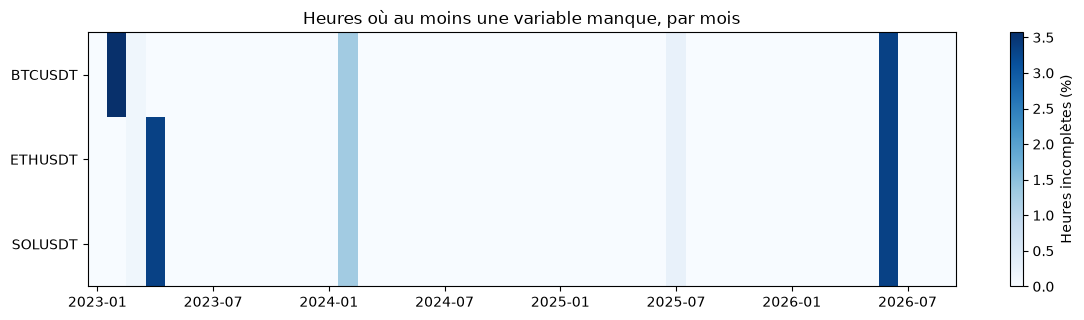

In [3]:
descriptif.graphique_manquants(descriptif.manquants_par_mois(panel))

Les données sont presque complètes : sur 32 856 heures par crypto, aucune variable ne manque plus de 0,15 % du temps. Les trous ont trois origines, toutes chez Binance :
- **la basis** (indice de prime) manque sur des journées entières : le 24 février 2023 pour BTC, le 9 avril 2023 pour ETH et SOL, et le 29 juin 2026 pour les trois. Ce sont les bandes foncées de la carte ;
- **les relevés à 5 minutes** (open interest et ratios) manquent pendant 9 heures le 16 février 2024, sur les trois cryptos à la fois ;
- une heure de spot (24 mars 2023) et deux heures du ratio des gros traders en comptes (22 juillet 2025).

Ces trous sont trop courts pour biaiser l'analyse, et on ne les comble pas. Aucune des variables de la cible (prix, open interest, volumes) ne manque plus de 9 heures.

### Cohérence du ratio taker

La condition C3 de la cible utilise le ratio taker (achats agressifs / ventes agressives). Binance le donne de deux façons :
- **les relevés à 5 minutes** (`taker_ratio` du panel, moyenne des 12 relevés de l'heure) ;
- **les bougies horaires** : `taker_buy_volume / (volume − taker_buy_volume)`.

On compare les deux, heure par heure.

In [4]:
descriptif.comparer_taker(panel).round(3)

,Médiane bougies,Médiane relevés,Médiane relevés / bougies,Corrélation des log,Même côté de 1 (%)
BTCUSDT,0.988,1.094,1.101,0.705,70.222
ETHUSDT,0.984,1.077,1.088,0.688,70.435
SOLUSDT,0.977,1.046,1.064,0.732,73.938


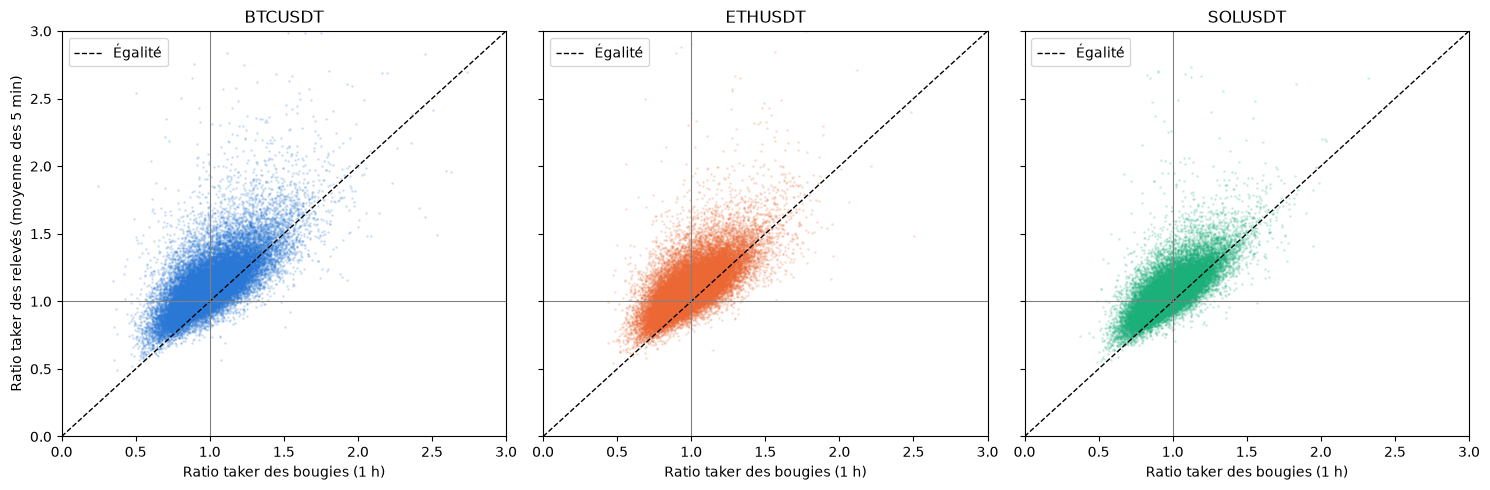

In [5]:
descriptif.graphique_taker(panel)

Les deux mesures vont dans le même sens (corrélation des logarithmes autour de 0,7), mais les relevés sont **6 à 10 % plus élevés** : leur médiane dépasse 1, celle des bougies est en dessous, et le nuage est au-dessus de la diagonale. L'écart vient du calcul : une moyenne de douze ratios est plus grande que le ratio des volumes de l'heure, car un ratio fluctue de façon asymétrique (il ne descend pas sous 0 mais peut monter très haut).

Pour C3, dont le seuil est justement 1, ce choix compte : les deux mesures ne sont du même côté de 1 que 70 à 74 % des heures. Avec la moyenne des relevés, C3 serait vraie plus souvent sans que les acheteurs dominent vraiment. **La cible utilise donc le ratio des bougies**, qui rapporte les volumes réellement échangés pendant l'heure.

### Les trois cryptos

In [6]:
descriptif.tableau_cryptos(panel).round(2)

,Volume quotidien moyen (Md USDT),Open interest moyen (Md USDT),Volatilité annualisée (%),Rendement total (%),Funding moyen annualisé (%),Heures à funding négatif (%),Volume perpétuel / volume spot
BTCUSDT,14.62,5.91,46.08,405.70,7.24,13.56,6.90
ETHUSDT,9.80,3.67,61.14,124.87,7.37,13.90,8.67
SOLUSDT,2.63,0.83,86.31,1082.98,3.86,30.41,5.49


Les trois cryptos ne sont pas comparables en niveau :
- **taille** : BTC échange 14,6 milliards d'USDT par jour sur le perpétuel, SOL cinq fois moins ;
- **volatilité** : SOL est presque deux fois plus volatile que BTC (86 % contre 46 % par an) ;
- **période** : très haussière, de +125 % (ETH) à +1 083 % (SOL), car elle part du creux de fin 2022 ;
- **funding** : positif en moyenne (environ 7 % par an sur BTC et ETH) : les longs paient presque toujours les shorts. Il n'est négatif que 14 % des heures sur BTC et ETH, contre **30 % sur SOL**. Les shorts dominent donc plus souvent sur SOL, la crypto où H2 prévoit le plus de squeezes.

Conséquence : la cible et les variables doivent être relatives à chaque crypto (seuil en écarts-types dans C1, variation relative de l'open interest dans C2, variables normalisées par crypto), pas en niveau.

### Distribution des rendements horaires

In [7]:
descriptif.queues_rendements(panel).round(4)

,Asymétrie,Kurtosis (excès),Au-delà de 4 σ (%)
BTCUSDT,-0.1551,13.2913,0.8644
ETHUSDT,-0.3570,18.1172,0.7792
SOLUSDT,0.1843,11.3202,0.6513
Loi normale,0.0000,0.0000,0.0063


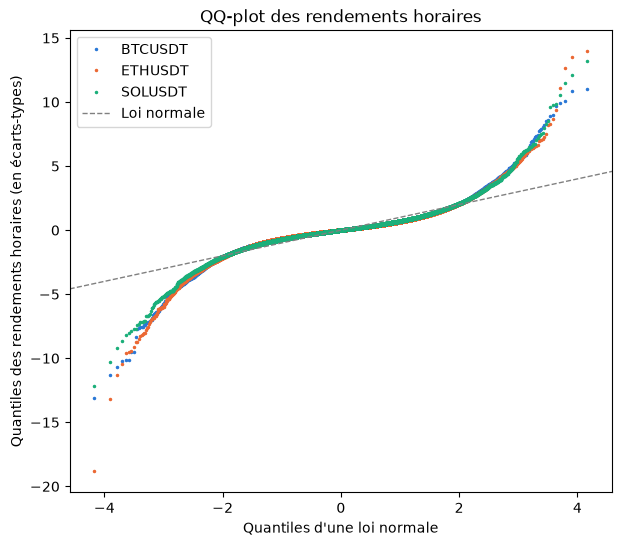

In [8]:
descriptif.graphique_qqplot(panel)

Les rendements horaires ont des **queues très épaisses** : la kurtosis en excès va de 11 à 18 (0 pour une loi normale), et 0,65 à 0,86 % des heures dépassent 4 écarts-types, soit 100 à 140 fois plus qu'avec une loi normale. Sur le QQ-plot, les points quittent la droite dès 2 écarts-types.

Deux conséquences pour la cible :
- **un seuil en écarts-types** est nécessaire, car une même hausse n'a pas le même sens partout. Sur la période, 3·σ·√24 vaut environ 7 % pour BTC, 10 % pour ETH et 14 % pour SOL (volatilité annualisée / √365 × 3). Le plancher de 5 % ne joue donc que dans les périodes calmes ;
- **3 écarts-types ne sont pas un événement à 0,1 %** comme pour une loi normale : les fortes hausses sont plus fréquentes que ne le suggère σ. C'est C2 et C3 qui rendent la cible rare, pas seulement C1.

### Volume du perpétuel et du spot

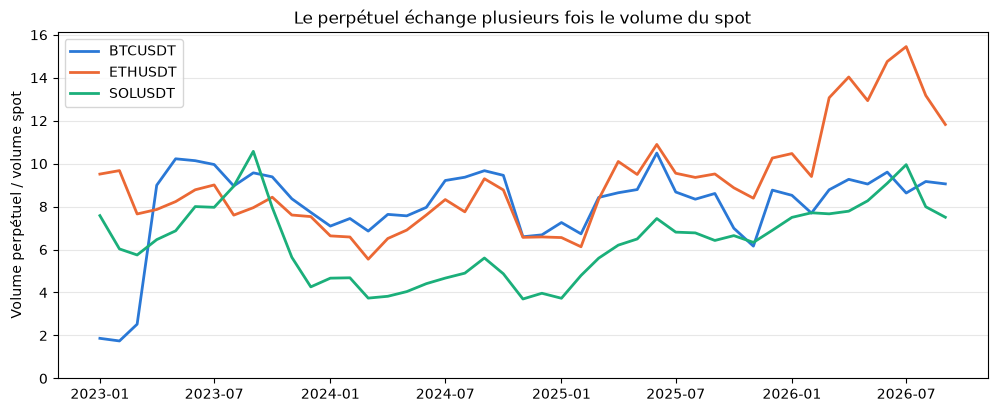

In [9]:
descriptif.graphique_perp_spot(descriptif.ratio_perp_spot_mensuel(panel))

Le perpétuel échange en moyenne **5 à 9 fois le volume du spot** (dernière colonne du tableau des cryptos) : sur ces trois cryptos, l'essentiel des échanges se fait avec levier. C'est ce qui donne du sens à la question : un rachat forcé de shorts sur le perpétuel peut déplacer le prix.

Le rapport varie dans le temps. Il est très bas sur BTC jusqu'en mars 2023 (moins de 3), très probablement parce que Binance supprimait alors les frais sur le spot de BTC, ce qui gonflait son volume. Il monte aussi sur ETH en 2026, jusqu'à 15. S'il sert de variable, il faudra donc le normaliser par crypto et dans le temps.

### Bilan de l'étape 1

- Les données sont fiables : moins de 0,15 % de valeurs manquantes, toujours sur des trous communs venant de Binance.
- Le ratio taker se mesure avec les bougies, pas avec la moyenne des relevés à 5 minutes, qui le surestime.
- Les cryptos diffèrent en taille et en volatilité, et leurs rendements ont des queues épaisses : la cible et les variables doivent être relatives à chaque crypto.

## 2. Variables de positionnement

On décrit les variables qui serviront à départager H1 et H2 :
- **funding** : taux payé par les longs aux shorts (s'il est positif), ramené à 8 h ;
- **variation de l'open interest sur 24 h** : entrée (hausse) ou sortie (baisse) de positions ;
- **trois ratios long/short (L/S)** : nombre de comptes longs divisé par le nombre de comptes courts, pour tous les comptes ou pour les gros traders (les 20 % de comptes qui ont le plus de marge chez Binance), et, pour les gros traders, le même rapport pondéré par la taille des positions ;
- **ratio taker** : achats agressifs / ventes agressives de l'heure, calculé avec les bougies (voir l'étape 1) ;
- **basis** : écart entre le prix du perpétuel et l'indice au comptant.

In [10]:
variables = descriptif.positionnement(panel)
descriptif.resume_positionnement(variables).round(3)

Min     1 %  Médiane    99 %     Max
Funding (% par 8 h)         BTCUSDT  -0.015  -0.008    0.006   0.044   0.088
                            ETHUSDT  -0.037  -0.009    0.006   0.046   0.102
                            SOLUSDT  -0.927  -0.040    0.005   0.056   0.119
Variation OI 24 h (%)       BTCUSDT -25.882  -9.696   -0.010   9.255  24.883
                            ETHUSDT -28.755 -10.281    0.010  11.664  42.471
                            SOLUSDT -29.217 -12.718   -0.062  14.487  58.115
L/S tous comptes            BTCUSDT   0.418   0.530    1.361   2.974   4.173
                            ETHUSDT   0.521   0.782    2.149   4.975   6.314
                            SOLUSDT   0.536   0.814    2.409   5.004   6.029
L/S gros traders, comptes   BTCUSDT   0.503   0.632    1.414   3.218   5.148
                            ETHUSDT   0.537   0.795    2.249   6.224   8.587
                            SOLUSDT   0.574   0.857    2.546   5.513   6.481
L/S gros traders, positions BTCUSDT   0.683   0.790    1.379   2.406   2.821
                            ETHUSDT   0.878   1.027    1.778   4.496   6.120
                            SOLUSDT   0.858   0.940    1.763   3.468   3.961
Ratio taker                 BTCUSDT   0.243   0.609    0.988   1.594   2.739
                            ETHUSDT   0.435   0.645    0.984   1.515   3.332
                            SOLUSDT   0.372   0.654    0.977   1.440   2.320
Basis (%)                   BTCUSDT  -0.816  -0.075   -0.041   0.103   0.427
                            ETHUSDT  -0.659  -0.082   -0.040   0.105   0.568
                            SOLUSDT  -2.067  -0.113   -0.041   0.125   1.096

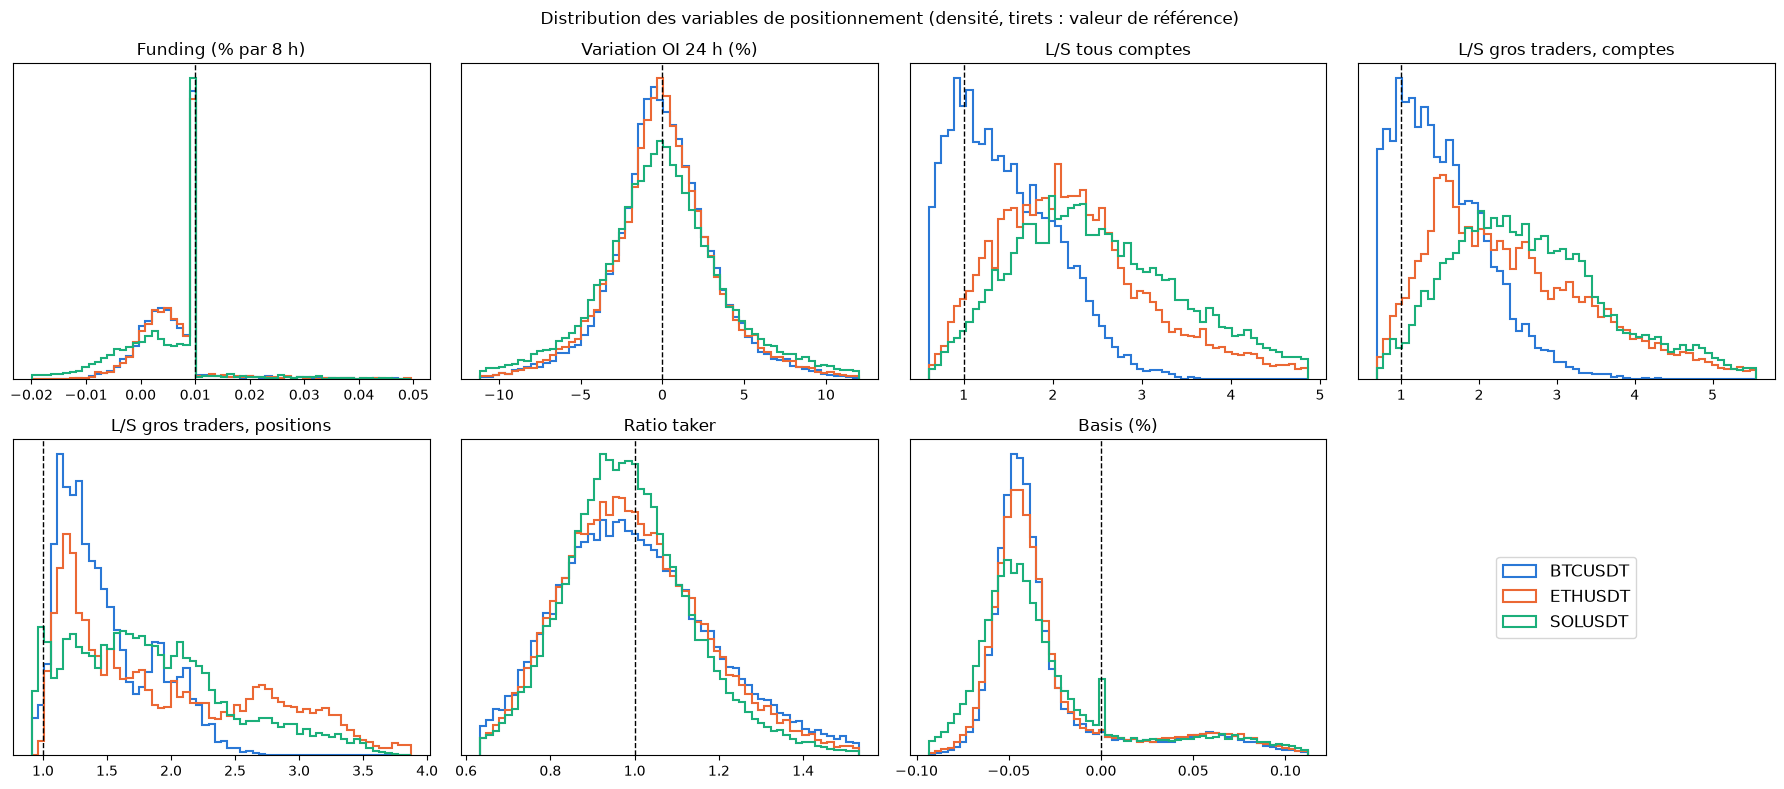

In [11]:
descriptif.graphique_distributions(variables)

- **Funding** : une grande partie des heures tombe exactement sur 0,01 % par 8 h, le taux par défaut de Binance (pic du premier histogramme). Le reste est surtout un peu en dessous ; au-dessus, il ne dépasse 0,044 à 0,056 % que 1 % du temps. Le minimum, −0,93 % par 8 h sur SOL le 4 janvier 2023, tombe pendant la hausse de SOL de janvier 2023 : les shorts payaient très cher pour rester en position. C'est le cas typique de H2, à retrouver dans la cible à l'étape 3.
- **Ratios L/S en comptes** : presque toujours au-dessus de 1 (médiane 1,4 pour BTC, 2,1 pour ETH, 2,4 pour SOL). En nombre de comptes, les longs dominent. « Beaucoup de shorts » ne peut donc pas vouloir dire un ratio sous 1 : il faut une mesure relative au niveau habituel de chaque crypto.
- **Ratio L/S des gros traders en positions** : plus proche de 1 et jamais sous 0,68.
- **Ratio taker** : centré un peu sous 1 (0,98) et assez symétrique ; 98 % des heures sont entre 0,61 et 1,59.
- **Variation de l'open interest** : dans ±10 à 15 % sur 24 h pour 98 % des heures, avec des chutes de 26 à 29 % (krachs) et une hausse de 58 % sur SOL.
- **Basis** : négative en médiane (−0,04 %), avec une seconde bosse vers +0,05 à +0,10 %, surtout dans les phases de hausse (fin 2023 à mars 2024, novembre 2024). Le petit pic à exactement 0 (1,7 % des heures de SOL, surtout en 2023) reste à expliquer.

### Le funding au taux par défaut

Binance verse le taux par défaut quand la prime du perpétuel sur l'indice est faible. Part des heures où le funding est sous, au ou au-dessus de ce taux, par année :

In [12]:
descriptif.position_du_funding(panel).round(1)

En dessous  Au taux par défaut  Au-dessus
symbol  année                                           
BTCUSDT 2023         55.2                38.5        6.3
        2024         38.5                42.1       19.4
        2025         82.8                17.2        0.0
        2026         93.2                 6.8        0.0
ETHUSDT 2023         55.8                37.2        7.0
        2024         38.3                39.6       22.0
        2025         80.6                19.4        0.0
        2026         94.6                 5.4        0.0
SOLUSDT 2023         49.9                41.2        9.0
        2024         40.6                36.7       22.7
        2025         80.5                19.3        0.2
        2026         86.7                13.3        0.0

Deux régimes se succèdent. En 2023-2024, le funding est au taux par défaut environ 40 % des heures et au-dessus 6 à 23 % des heures. En 2025-2026, il est en dessous 80 à 95 % des heures et **presque jamais au-dessus** (0,2 % des heures au plus) : les longs ne paient plus de prime. La même rupture apparaît sur Bybit, ce n'est donc pas une erreur des fichiers Binance. Une valeur au taux par défaut dit seulement que le marché n'est pas tendu ; l'information est dans les écarts à ce taux, et leur sens a changé entre les deux périodes. Pour les variables, on utilisera donc l'écart au taux par défaut plutôt que le niveau.